# Deep q-Gaussian classification

A companion to `DeepTPDA.ipynb` using `SimplexQGaussianHead` and
`QGaussianRegFYLoss` from `qgda.py`.

Keep the same three bivariate TP **input** classes, including the overlap
between classes 0 and 1, the 80/20 train/test split, and the two-hidden-layer
backbone. The head uses fixed simplex means and a fixed spherical shape;
only the backbone and class-prior logits are optimized. Its default actual
within-class covariance is $I_D/D$.

Set `q < 1` below: `q=0` gives TP and `q=0.5` gives biweight densities.
For $k=1/(1-q)$, the head returns joint densities

$$
p(c,z)=\pi_c\left[\frac{-\tau-Q_c(z)/2}{k}\right]_+^k,
\qquad Q_c(z)=\frac{\|z-\mu_c\|^2}{v}.
$$

Train with `QGaussianRegFYLoss`: the mean joint FY loss at $\alpha=2-q$
plus class-wise projected characteristic-function matching to the same q-Gaussian
target. The FY term retains embedding gradients outside support. A point
outside every support receives prediction
`-1` and counts as incorrect. Report accuracy and coverage together.

Run from `EDA/` with PyTorch, NumPy, and Matplotlib installed.

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.colors import ListedColormap
from matplotlib.patches import Circle
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from qgda import (
    SimplexQGaussianHead, QGaussianRegFYLoss, sample_qgaussian_residuals,
)

seed = 13
q = 0.5
q_weight = 1.0
num_slices, num_integration_points = 256, 65
K, input_dim, feature_dim = 3, 2, 2
n_per_class = 1800
hidden_dim, batch_size, num_epochs = 32, 256, 50
learning_rate = 0.01
plot_dir = Path('plots')

torch.manual_seed(seed)
rng = np.random.default_rng(seed)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device, '| head q:', q)

device: cuda | head q: 0.5


## The same TP input distributions

The input distributions stay TP regardless of the head's `q`.
Draw exact spherical TP residuals, then apply each input class's Cholesky
factor and normalization scale. This replaces rejection sampling with the
shared exact sampler.

In [2]:
mu_true = np.array([
    [-0.9, -0.2],
    [0.6, 0.1],
    [2.8, 2.5],
])
Sigma_true = np.array([
    [[1.10, 0.30], [0.30, 0.95]],
    [[1.05, -0.25], [-0.25, 0.90]],
    [[0.70, 0.08], [0.08, 0.65]],
])


def sample_input_class(mu, cov, count, generator):
    tau = -(math.gamma(input_dim / 2 + 2) / np.sqrt(np.linalg.det(2 * np.pi * cov))) ** (2 / (input_dim + 2))
    residuals = sample_qgaussian_residuals(
        count, input_dim, q=0, radius=math.sqrt(-2 * tau),
        generator=generator, dtype=torch.float64,
    )
    return mu + residuals.numpy() @ np.linalg.cholesky(cov).T


generator = torch.Generator().manual_seed(seed)
X = np.vstack([
    sample_input_class(mu, cov, n_per_class, generator)
    for mu, cov in zip(mu_true, Sigma_true)
])
y = np.repeat(np.arange(K), n_per_class)
order = rng.permutation(len(X))
X, y = X[order], y[order]
n_train = int(0.8 * len(X))
X_train, X_test = X[:n_train], X[n_train:]
y_train, y_test = y[:n_train], y[n_train:]
print('Train:', X_train.shape, '| test:', X_test.shape)
print('Class counts (train):', np.bincount(y_train, minlength=K))

Train: (4320, 2) | test: (1080, 2)
Class counts (train): [1453 1439 1428]


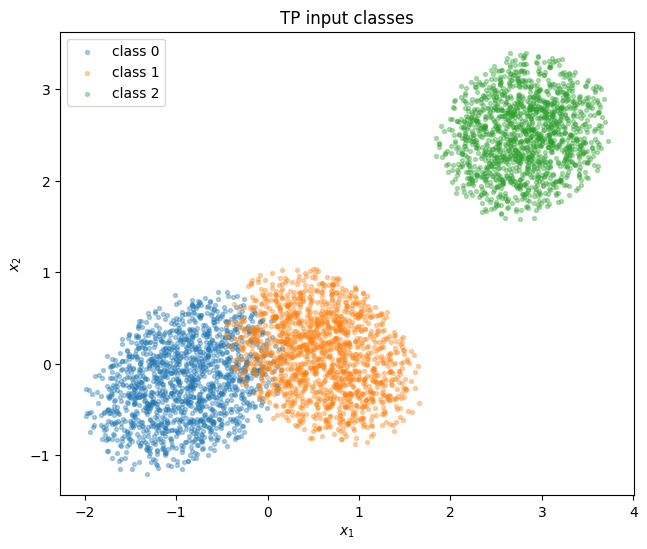

In [3]:
colors = ['tab:blue', 'tab:orange', 'tab:green']
fig, ax = plt.subplots(figsize=(7.4, 6.4))
for c, color in enumerate(colors):
    points = X_train[y_train == c]
    ax.scatter(points[:, 0], points[:, 1], s=8, alpha=0.35, color=color, label=f'class {c}')
ax.set(title='TP input classes', xlabel='$x_1$', ylabel='$x_2$', aspect='equal')
ax.legend()
plt.show()

## Two-hidden-layer backbone and fixed simplex head

The backbone matches `DeepTPDA.ipynb`: two width-32 ReLU layers and a
2D embedding. The head keeps pairwise mean distance 6 and chooses its fixed
shape from `q`. The shape matrix and the actual moment covariance differ.

In [4]:
class QGaussianNet(nn.Module):
    def __init__(self, num_classes, input_dim=2, hidden_dim=32, feature_dim=2, q=0.5):
        super().__init__()
        self.backbone = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, feature_dim),
        )
        self.head = SimplexQGaussianHead(num_classes, feature_dim, q=q)

    def forward(self, x):
        return self.head(self.backbone(x))


def predict(scores):
    return scores.argmax(1).masked_fill(scores.max(1).values <= 0, -1)


@torch.no_grad()
def evaluate(model, x, target):
    model.eval()
    prediction = predict(model(x))
    return {
        'accuracy': (prediction == target).float().mean().item(),
        'coverage': (prediction >= 0).float().mean().item(),
    }


model = QGaussianNet(K, input_dim, hidden_dim, feature_dim, q=q).to(device)
print('Fixed simplex means:\n', model.head.mu.detach().cpu())
print('Fixed shape matrix:\n', model.head.covariance.detach().cpu())
print('Actual moment covariance:\n', model.head.moment_covariance.detach().cpu())
print('Support radius:', model.head.support_radius.item())

Fixed simplex means:
 tensor([[ 5.4491e-08, -3.4641e+00],
        [-3.0000e+00,  1.7321e+00],
        [ 3.0000e+00,  1.7321e+00]])
Fixed shape matrix:
 tensor([[2.0467, 0.0000],
        [0.0000, 2.0467]])
Actual moment covariance:
 tensor([[0.5000, 0.0000],
        [0.0000, 0.5000]])
Support radius: 2.0


## Train with QGaussianRegFYLoss

Use the same Adam learning rate (0.01), batch size (256), and 10 epochs as
the template. `q_weight` controls CF matching strength (default 1.0); the
regularizer uses the same `q` as the head. Advance `step` each minibatch to
resample the projection directions. Regularization is active from the first
batch. The test split reports accuracy and coverage; it does not
select a checkpoint. All-zero density scores count as uncovered and incorrect.

In [5]:
Xtr = torch.as_tensor(X_train, dtype=torch.float32, device=device)
ytr = torch.as_tensor(y_train, dtype=torch.long, device=device)
Xte = torch.as_tensor(X_test, dtype=torch.float32, device=device)
yte = torch.as_tensor(y_test, dtype=torch.long, device=device)
train_loader = DataLoader(
    TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True,
    generator=torch.Generator().manual_seed(seed),
)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
criterion = QGaussianRegFYLoss(
    feature_dim, q=q, q_weight=q_weight, num_slices=num_slices,
    num_points=num_integration_points, seed=seed,
).to(device)
history = []
step = 0

for epoch in range(1, num_epochs + 1):
    model.train()
    loss_sum = 0.0
    for xb, yb in train_loader:
        z = model.backbone(xb)
        loss = criterion(model.head, z, yb, step=step)
        if not torch.isfinite(loss):
            raise RuntimeError(f'Non-finite regularized FY loss at epoch {epoch}')
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        step += 1
        loss_sum += loss.item() * len(yb)

    train = evaluate(model, Xtr, ytr)
    test = evaluate(model, Xte, yte)
    row = dict(epoch=epoch, loss=loss_sum / len(ytr),
               train_accuracy=train['accuracy'], test_accuracy=test['accuracy'],
               train_coverage=train['coverage'], test_coverage=test['coverage'])
    history.append(row)
    if epoch == 1 or epoch % 10 == 0 or epoch == num_epochs:
        print(f"epoch {epoch:3d} | loss={row['loss']:.5f} | "
              f"train acc={train['accuracy']:.4f}, coverage={train['coverage']:.4f} | "
              f"test acc={test['accuracy']:.4f}, coverage={test['coverage']:.4f}")

print('Learned class priors:', model.head.priors().detach().cpu().numpy())

epoch   1 | loss=169.28687 | train acc=0.6227, coverage=0.7861 | test acc=0.6222, coverage=0.7769
epoch  10 | loss=5.27098 | train acc=0.9148, coverage=0.9285 | test acc=0.9250, coverage=0.9380
epoch  20 | loss=4.33919 | train acc=0.9380, coverage=0.9523 | test acc=0.9417, coverage=0.9574
epoch  30 | loss=3.93631 | train acc=0.9449, coverage=0.9616 | test acc=0.9491, coverage=0.9648
epoch  40 | loss=4.22090 | train acc=0.9475, coverage=0.9655 | test acc=0.9519, coverage=0.9685
epoch  50 | loss=3.07538 | train acc=0.9530, coverage=0.9727 | test acc=0.9537, coverage=0.9722
Learned class priors: [0.27640304 0.31509304 0.40850395]


## Learned embeddings and decision regions

Shading comes directly from the head. Gray marks points outside every
class support, crosses mark the fixed means, and dashed circles mark support
boundaries. Overlapping input classes need not map perfectly into the disjoint
embedding supports.

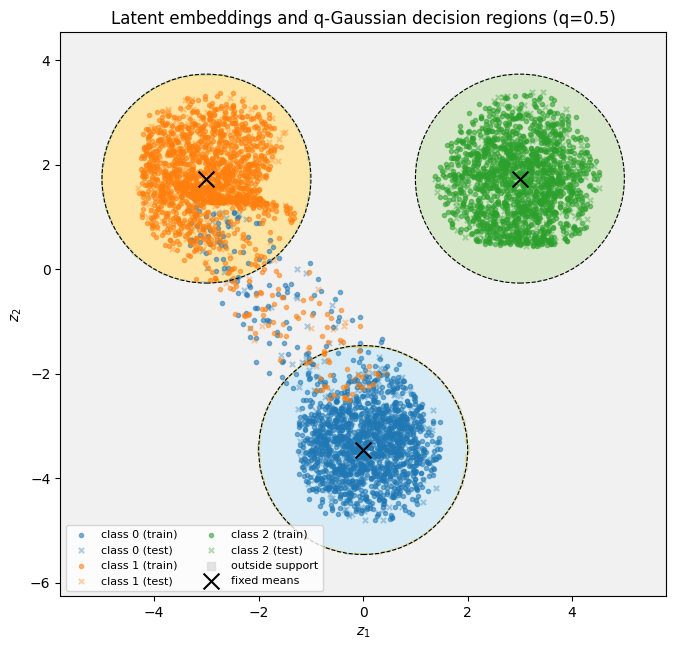

In [6]:
assert feature_dim == 2, 'The latent-space plot requires two embedding dimensions.'
with torch.no_grad():
    z_tr = model.backbone(Xtr).cpu().numpy()
    z_te = model.backbone(Xte).cpu().numpy()
    centers = model.head.mu.cpu().numpy()
    radius = model.head.support_radius.item()

# Include every class support even if the encoder leaves one empty.
all_points = np.vstack([z_tr, z_te, centers - radius, centers + radius])
low, high = all_points.min(0) - 0.8, all_points.max(0) + 0.8
zz1, zz2 = np.meshgrid(np.linspace(low[0], high[0], 300), np.linspace(low[1], high[1], 300))
grid = torch.as_tensor(np.c_[zz1.ravel(), zz2.ravel()], dtype=Xtr.dtype, device=device)
with torch.no_grad():
    regions = predict(model.head(grid)).cpu().numpy()
regions = np.where(regions < 0, K, regions).reshape(zz1.shape)

fig, ax = plt.subplots(figsize=(8.6, 6.6))
region_colors = ['#8ecae6', '#ffb703', '#90be6d', '#d9d9d9']
ax.contourf(zz1, zz2, regions, levels=np.arange(K + 2) - 0.5,
            cmap=ListedColormap(region_colors), alpha=0.36)
for c, color in enumerate(colors):
    train_points, test_points = z_tr[y_train == c], z_te[y_test == c]
    ax.scatter(train_points[:, 0], train_points[:, 1], s=9, alpha=0.55,
               color=color, label=f'class {c} (train)')
    ax.scatter(test_points[:, 0], test_points[:, 1], s=14, alpha=0.35,
               color=color, marker='x', label=f'class {c} (test)')
    ax.add_patch(Circle(centers[c], radius, fill=False, linestyle='--', linewidth=0.8))
ax.scatter([], [], marker='s', color=region_colors[-1], alpha=0.7, label='outside support')
ax.scatter(centers[:, 0], centers[:, 1], c='black', marker='x', s=130, label='fixed means')
ax.set(title=f'Latent embeddings and q-Gaussian decision regions (q={q:g})',
       xlabel='$z_1$', ylabel='$z_2$', aspect='equal')
ax.legend(loc='best', fontsize=8, ncol=2)
fig.tight_layout()
plot_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(plot_dir / 'deep_qgaussian_latent_space.png', dpi=180, bbox_inches='tight')
plt.show()

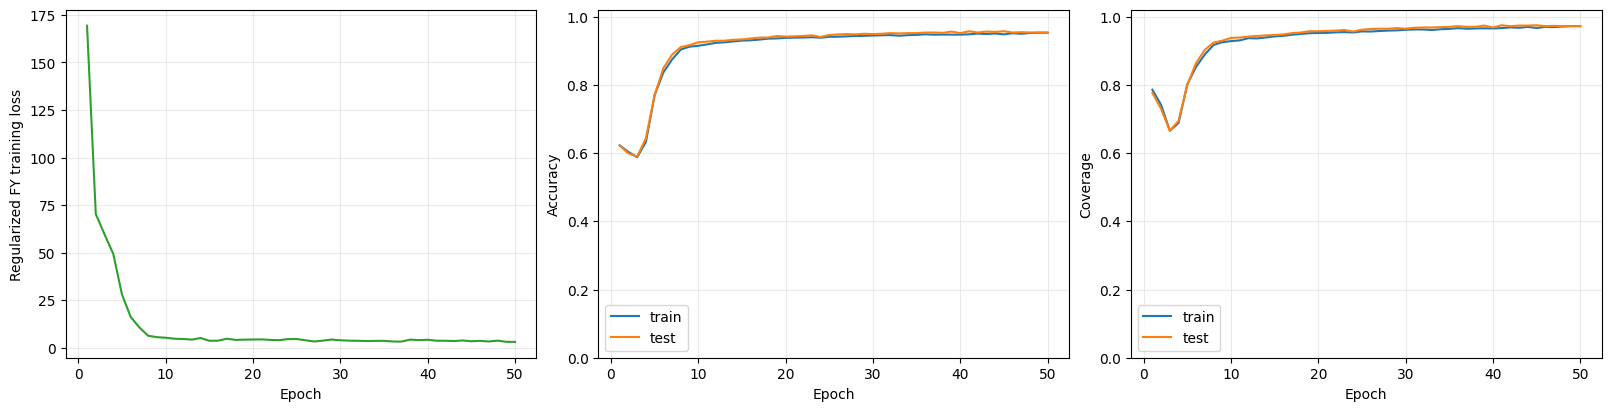

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
epochs = [row['epoch'] for row in history]
axes[0].plot(epochs, [row['loss'] for row in history], color='tab:green')
axes[0].set(ylabel='Regularized FY training loss')
for ax, metric in zip(axes[1:], ('accuracy', 'coverage')):
    for split in ('train', 'test'):
        ax.plot(epochs, [row[f'{split}_{metric}'] for row in history], label=split)
    ax.set(ylabel=metric.capitalize(), ylim=(0, 1.02))
    ax.legend()
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.grid(alpha=0.25)
plt.show()